In [1]:
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

BASE_DIR = Path("/content/drive/MyDrive/Colab Notebooks/data")
PROCESSED_DIR = BASE_DIR / "processed"
SELECTION_DIR = BASE_DIR / "feature_selection"

RESULTS_DIR = Path("/content/drive/MyDrive/Colab Notebooks/results")
MODEL_DIR = RESULTS_DIR / "models"
OUTPUT_DIR = RESULTS_DIR / "feature_importance"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Feature selection folder:", SELECTION_DIR)
print("Models folder:", MODEL_DIR)
print("Output folder:", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Feature selection folder: /content/drive/MyDrive/Colab Notebooks/data/feature_selection
Models folder: /content/drive/MyDrive/Colab Notebooks/results/models
Output folder: /content/drive/MyDrive/Colab Notebooks/results/feature_importance


In [2]:
print("Model files:")
for file in sorted(MODEL_DIR.glob("*"))[:20]:
    print(file.name)

print("\nFeature-selection files:")
for file in sorted(SELECTION_DIR.glob("*"))[:30]:
    print(file.name)

print("\nTotal model files:", len(list(MODEL_DIR.glob("*"))))
print("Total feature-selection files:", len(list(SELECTION_DIR.glob("*"))))

Model files:
RadioClinLab_ICU_lightgbm.joblib
RadioClinLab_ICU_logistic_regression.joblib
RadioClinLab_ICU_mlp.joblib
RadioClinLab_ICU_random_forest.joblib
RadioClinLab_ICU_svm.joblib
RadioClinLab_death_lightgbm.joblib
RadioClinLab_death_logistic_regression.joblib
RadioClinLab_death_mlp.joblib
RadioClinLab_death_random_forest.joblib
RadioClinLab_death_svm.joblib
RadioClinLab_mechanical_ventilation_lightgbm.joblib
RadioClinLab_mechanical_ventilation_logistic_regression.joblib
RadioClinLab_mechanical_ventilation_mlp.joblib
RadioClinLab_mechanical_ventilation_random_forest.joblib
RadioClinLab_mechanical_ventilation_svm.joblib
RadioClin_ICU_lightgbm.joblib
RadioClin_ICU_logistic_regression.joblib
RadioClin_ICU_mlp.joblib
RadioClin_ICU_random_forest.joblib
RadioClin_ICU_svm.joblib

Feature-selection files:
RadioClinLab_ICU_X_test_selected.npy
RadioClinLab_ICU_X_train_selected.npy
RadioClinLab_ICU_lasso_model.joblib
RadioClinLab_ICU_selected_features.csv
RadioClinLab_ICU_selected_indices.npy

In [3]:
import pandas as pd

summary_candidates = list(SELECTION_DIR.glob("*.csv"))

print("CSV files found:")
for file in summary_candidates:
    print(file.name)

CSV files found:
Radiom_ICU_selected_features.csv
Radiom_mechanical_ventilation_selected_features.csv
Radiom_death_selected_features.csv
RadioClin_ICU_selected_features.csv
RadioClin_mechanical_ventilation_selected_features.csv
RadioClin_death_selected_features.csv
RadioClinLab_ICU_selected_features.csv
RadioClinLab_mechanical_ventilation_selected_features.csv
RadioClinLab_death_selected_features.csv
lasso_selection_summary.csv


In [4]:

SUMMARY_PATH = SELECTION_DIR / "lasso_selection_summary.csv"

if SUMMARY_PATH.exists():
    selection_summary = pd.read_csv(SUMMARY_PATH)
    display(selection_summary.head())
else:
    print("Summary CSV not found at:", SUMMARY_PATH)
    print("Use the exact CSV filename shown in Cell 3.")

,Feature Group,Target,Original Features,Selected Features,Features Removed
0,Radiom,ICU,120,113,7
1,Radiom,mechanical_ventilation,120,115,5
2,Radiom,death,120,109,11
3,RadioClin,ICU,147,131,16
4,RadioClin,mechanical_ventilation,147,129,18


In [5]:
import joblib
import numpy as np
import pandas as pd

GROUP = "RadioClinLab"
TARGET = "ICU"

model_files = list(MODEL_DIR.glob("*.joblib"))

matching_models = [
    f for f in model_files
    if GROUP.lower() in f.name.lower()
    and TARGET.lower() in f.name.lower()
]

print("Matching models:")
for file in matching_models:
    print(file.name)

Matching models:
RadioClinLab_ICU_logistic_regression.joblib
RadioClinLab_ICU_random_forest.joblib
RadioClinLab_ICU_svm.joblib
RadioClinLab_ICU_mlp.joblib
RadioClinLab_ICU_lightgbm.joblib


In [6]:

MODEL_PATH = next(
    (
        f for f in matching_models
        if "logistic_regression" in f.name.lower()
    ),
    matching_models[0] if matching_models else None
)

if MODEL_PATH is None:
    raise FileNotFoundError(
        "No matching RadioClinLab ICU model found. "
        "Check the filenames printed in Cell 2."
    )

model = joblib.load(MODEL_PATH)

print("Loaded model:", MODEL_PATH.name)
print("Model type:", type(model).__name__)

Loaded model: RadioClinLab_ICU_logistic_regression.joblib
Model type: LogisticRegression


In [7]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

def load_matrix(path):
    if path.suffix == ".npy":
        return np.load(path, allow_pickle=False)

    if path.suffix == ".npz":
        loaded = np.load(path, allow_pickle=False)
        key = loaded.files[0]
        return loaded[key]

    raise ValueError(f"Unsupported file format: {path}")

# Locate the selected test matrix and selected feature indices.
test_candidates = list(
    SELECTION_DIR.glob(f"{GROUP}_{TARGET}*test*.npy")
) + list(
    SELECTION_DIR.glob(f"{GROUP}_{TARGET}*test*.npz")
)

index_candidates = list(
    SELECTION_DIR.glob(f"{GROUP}_{TARGET}*indices*.npy")
)

print("Test matrix candidates:", [f.name for f in test_candidates])
print("Index candidates:", [f.name for f in index_candidates])

Test matrix candidates: ['RadioClinLab_ICU_X_test_selected.npy']
Index candidates: ['RadioClinLab_ICU_selected_indices.npy']


In [8]:
if not test_candidates:
    raise FileNotFoundError(
        "Selected test matrix not found. Check the filenames above."
    )

if not index_candidates:
    raise FileNotFoundError(
        "Selected feature indices not found. Check the filenames above."
    )

X_test_selected = load_matrix(test_candidates[0])
selected_indices = np.load(index_candidates[0], allow_pickle=False)

y_test_path = PROCESSED_DIR / "Y_test.csv"
if not y_test_path.exists():
    raise FileNotFoundError(f"Could not find {y_test_path}")

y_test_df = pd.read_csv(y_test_path)
y_test = y_test_df[TARGET].to_numpy()

print("Test matrix shape:", X_test_selected.shape)
print("Test labels shape:", y_test.shape)
print("Selected indices:", len(selected_indices))

Test matrix shape: (720, 148)
Test labels shape: (720,)
Selected indices: 148


In [9]:
if len(X_test_selected) != len(y_test):
    raise ValueError("Test matrix and target labels have different row counts.")

importance_result = permutation_importance(
    model,
    X_test_selected,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "selected_feature_position": np.arange(X_test_selected.shape[1]),
    "importance_mean": importance_result.importances_mean,
    "importance_std": importance_result.importances_std
})

importance_df = importance_df.sort_values(
    "importance_mean",
    ascending=False
).reset_index(drop=True)

display(importance_df.head(20))

,selected_feature_position,importance_mean,importance_std
0,119,0.005158,0.001105
1,128,0.004551,0.000773
2,114,0.004203,0.001633
3,92,0.003739,0.001127
4,93,0.003724,0.001002
5,44,0.003097,0.000975
6,127,0.002953,0.000749
7,115,0.002939,0.000730
8,120,0.002471,0.000968
9,122,0.002125,0.000743


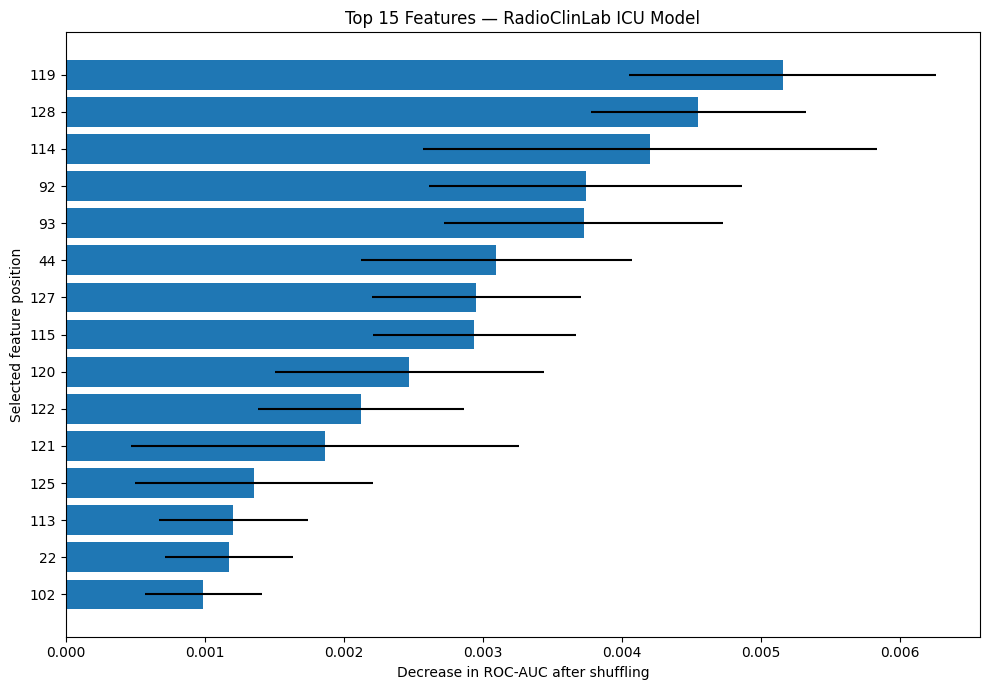

Saved plot: /content/drive/MyDrive/Colab Notebooks/results/feature_importance/radioclinlab_icu_feature_importance.png
Saved importance table: /content/drive/MyDrive/Colab Notebooks/results/feature_importance/radioclinlab_icu_feature_importance.csv


In [10]:
import matplotlib.pyplot as plt

top_features = importance_df.head(15).sort_values("importance_mean")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["selected_feature_position"].astype(str),
    top_features["importance_mean"],
    xerr=top_features["importance_std"]
)
plt.xlabel("Decrease in ROC-AUC after shuffling")
plt.ylabel("Selected feature position")
plt.title("Top 15 Features — RadioClinLab ICU Model")
plt.tight_layout()

plot_path = OUTPUT_DIR / "radioclinlab_icu_feature_importance.png"
plt.savefig(plot_path, dpi=200, bbox_inches="tight")
plt.show()

importance_csv = OUTPUT_DIR / "radioclinlab_icu_feature_importance.csv"
importance_df.to_csv(importance_csv, index=False)

print("Saved plot:", plot_path)
print("Saved importance table:", importance_csv)